# Antiscalant dosage: synthetic demonstration

Original industrial data cannot be shared. All data and results below are synthetic. This notebook demonstrates a newly written version of the workflow, not the original internship results.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
assert (root / "src").is_dir(), "Start Jupyter from the repository root."
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import matplotlib.pyplot as plt
from src.synthetic import generate
from src.preprocessing import prepare
from src.features import engineer, FEATURES
from src.modeling import evaluate
from src.plots import plot_results

## 1. Generate invented observations
Fixed seed, fictional UTC dates, dimensionless indices. Missing readings, invalid values and duplicate rows are deliberately injected. The generator is not a physical model.

In [2]:
process, lab = generate()
display(process.head(), lab.head())
display(process.isna().sum())

,timestamp,flow_index,temperature_index,dose_index
0,2024-01-01 00:00:00+00:00,0.980061,1.106112,1.465393
1,2024-01-01 01:00:00+00:00,1.016033,1.117873,1.514099
2,2024-01-01 02:00:00+00:00,0.968701,1.115034,1.417991
3,2024-01-01 03:00:00+00:00,1.058769,1.122785,1.558371
4,2024-01-01 04:00:00+00:00,1.016444,1.099906,1.428504


,available_at,salinity_index
0,2024-01-01 00:00:00+00:00,1.007618
1,2024-01-01 12:00:00+00:00,1.021592
2,2024-01-02 00:00:00+00:00,1.028819
3,2024-01-02 12:00:00+00:00,1.055564
4,2024-01-03 00:00:00+00:00,1.093234


timestamp             0
flow_index           40
temperature_index     0
dose_index            0
dtype: int64

## 2. Quality control and temporal alignment
Laboratory observations are joined by availability time, looking backward only. Stale results are excluded. Missing targets are dropped; predictor imputation is deferred until model training.

In [3]:
aligned, audit = prepare(process, lab)
print(audit)
assert (aligned.available_at.dropna() <= aligned.loc[aligned.available_at.notna(), "timestamp"]).all()
display(aligned.head())

{'duplicates_removed': 2, 'invalid_values_masked': 8, 'missing_lab_values': 12}


,timestamp,flow_index,temperature_index,dose_index,available_at,salinity_index,lab_age_hours
0,2024-01-01 00:00:00+00:00,0.980061,1.106112,1.465393,2024-01-01 00:00:00+00:00,1.007618,0.0
1,2024-01-01 01:00:00+00:00,1.016033,1.117873,1.514099,2024-01-01 00:00:00+00:00,1.007618,1.0
2,2024-01-01 02:00:00+00:00,0.968701,1.115034,1.417991,2024-01-01 00:00:00+00:00,1.007618,2.0
3,2024-01-01 03:00:00+00:00,1.058769,1.122785,1.558371,2024-01-01 00:00:00+00:00,1.007618,3.0
4,2024-01-01 04:00:00+00:00,1.016444,1.099906,1.428504,2024-01-01 00:00:00+00:00,1.007618,4.0


## 3. Feature engineering
The rolling mean excludes the current row and uses only past flow observations. No dosage-derived predictor is used. Current process measurements are assumed available at prediction time.

In [4]:
features = engineer(aligned)
display(features[FEATURES].head(8))

,flow_index,temperature_index,salinity_index,lab_age_hours,flow_previous_6h,salinity_flow_interaction
0,0.980061,1.106112,1.007618,0.0,NaN,0.987527
1,1.016033,1.117873,1.007618,1.0,0.980061,1.023774
2,0.968701,1.115034,1.007618,2.0,0.998047,0.976081
3,1.058769,1.122785,1.007618,3.0,0.988265,1.066835
4,1.016444,1.099906,1.007618,4.0,1.005891,1.024187
5,1.034583,1.105983,1.007618,5.0,1.008002,1.042465
6,1.100724,1.110105,1.007618,6.0,1.012432,1.109109
7,1.081454,1.102663,1.007618,7.0,1.032542,1.089692


## 4. Chronological evaluation
Earliest 80% for training, latest 20% for testing. Median imputation and scaling are learned within each training pipeline. Hyperparameters are fixed illustrative choices. The target is never imputed.

In [5]:
metrics, predictions, models, cut = evaluate(features)
print("Train:", features.timestamp.iloc[0], "to", features.timestamp.iloc[cut-1])
print("Test:", features.timestamp.iloc[cut], "to", features.timestamp.iloc[-1])
display(metrics.round(4))

Train: 2024-01-01 00:00:00+00:00 to 2024-02-17 23:00:00+00:00
Test: 2024-02-18 00:00:00+00:00 to 2024-02-29 23:00:00+00:00


,MAE,RMSE,R2
model,,,
Median baseline,0.0792,0.0971,-0.4340
Ridge,0.0573,0.0750,0.1453
PLS,0.0573,0.0753,0.1372
Huber,0.0569,0.0746,0.1546
Random Forest,0.0589,0.0758,0.1265


## 5. Visual diagnostics
Every point and metric below is synthetic. Ridge is a preselected example for diagnostic plots, not a claim of industrial model superiority.

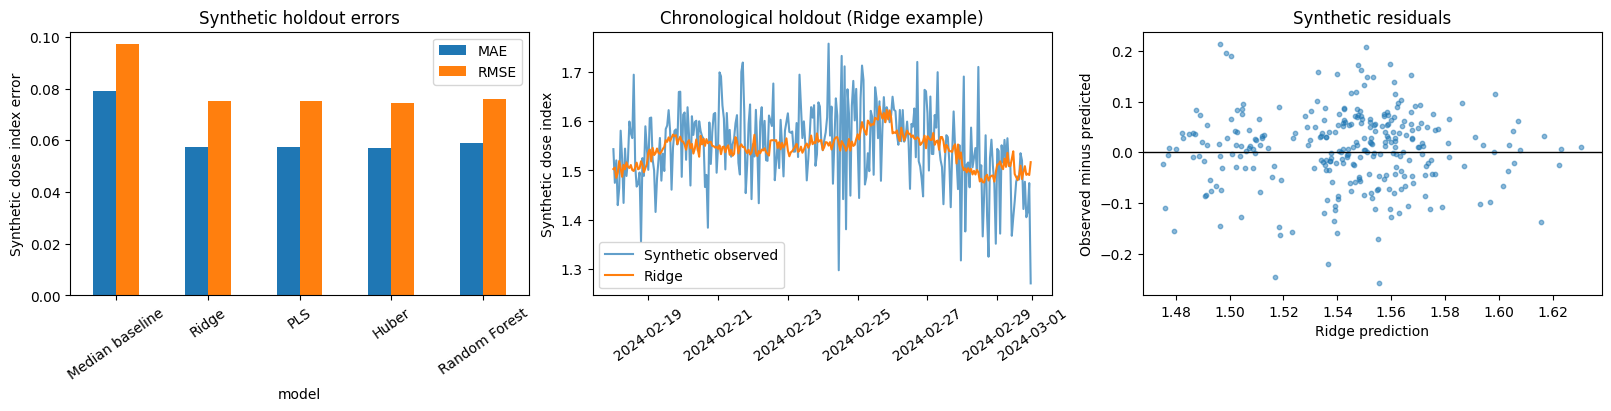

In [6]:
fig = plot_results(metrics, predictions)
plt.show()

## Limitations
The invented target follows a simple learnable equation. Scores cannot be transferred to the industrial project. A single chronological holdout does not characterize generalization across operating regimes. Predicting historical dose is not chemical optimization. No deployment or industrial benefit is claimed.